<a href="https://colab.research.google.com/github/RevanthTheBuilder/AI-ChatBox/blob/main/AI_STUDENT_ATTENDANCE_TRACKER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


ATTENDANCE REPORT
Student  Total_Classes  Attended  Attendance_Percentage  Absent         Status
   Asha            100        90             111.111111     -10 Low Attendance
  Rahul            100        60             166.666667     -40 Low Attendance
  Priya             80        72             111.111111      -8 Low Attendance
  Kiran            100        40             250.000000     -60 Low Attendance
  Sneha             90        81             111.111111      -9 Low Attendance
  Arjun            100        85             117.647059     -15 Low Attendance
  Meena             80        40             200.000000     -40 Low Attendance
   Ravi            100        75             133.333333     -25 Low Attendance
  Divya             90        45             200.000000     -45 Low Attendance
    Sai            100        95             105.263158      -5 Low Attendance


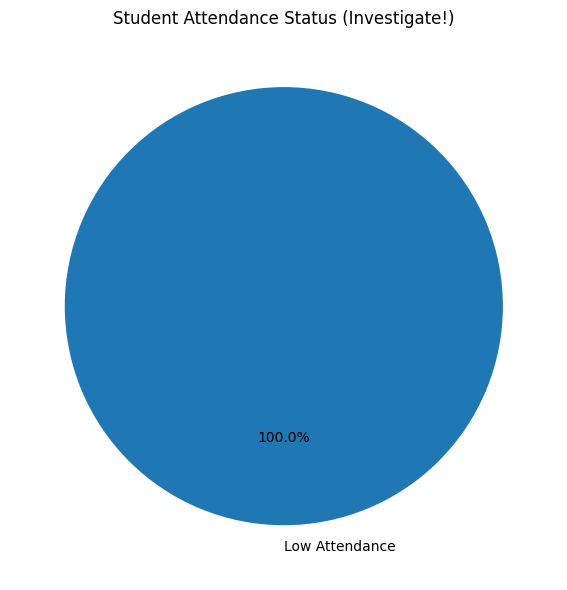

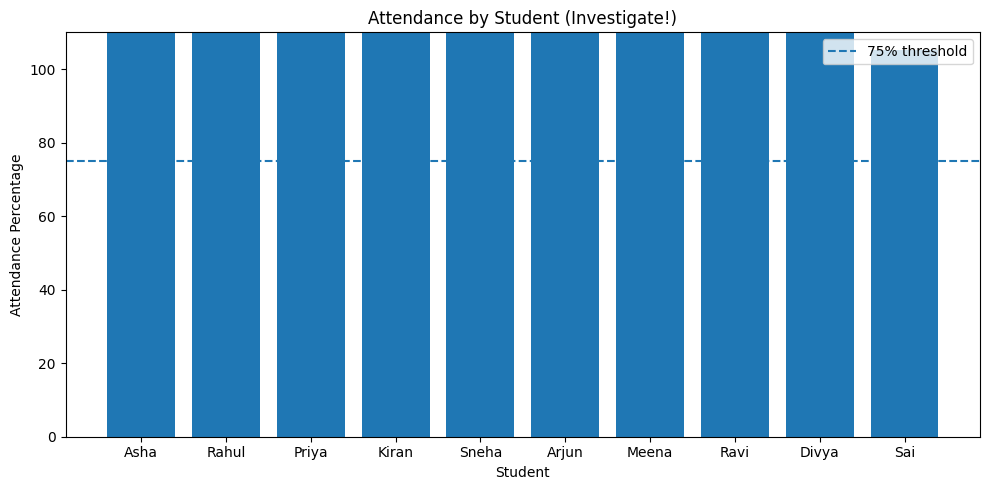


MODEL ACCURACY: 93.33 %
Confusion Matrix (Investigate!):
 [[ 12   5]
 [  3 100]]
New Student Result: At Risk


In [1]:

# PROGRAM 1: BUG HUNT
# Student Attendance Tracker + Pie Chart + Bar Graph + ML

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# ------------------------------------------------
# 1. STUDENT DATA
# ------------------------------------------------
df = pd.DataFrame({
    "Student": ["Asha", "Rahul", "Priya", "Kiran", "Sneha",
                "Arjun", "Meena", "Ravi", "Divya", "Sai"],
    "Total_Classes": [100, 100, 80, 100, 90, 100, 80, 100, 90, 100],
    "Attended": [90, 60, 72, 40, 81, 85, 40, 75, 45, 95]
})

# BUG 1: Incorrect percentage formula
df["Attendance_Percentage"] = (
    df["Total_Classes"] / df["Attended"] * 100
)

# BUG 2: Incorrect absent classes formula
df["Absent"] = df["Attended"] - df["Total_Classes"]

# BUG 3: Reversed status condition
df["Status"] = np.where(
    df["Attendance_Percentage"] >= 75,
    "Low Attendance",
    "Satisfactory"
)

print("\nATTENDANCE REPORT")
print(df.to_string(index=False))

# ------------------------------------------------
# 2. PIE CHART
# ------------------------------------------------
status_counts = df["Status"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Student Attendance Status (Investigate!)")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 3. BAR GRAPH
# ------------------------------------------------
plt.figure(figsize=(10, 5))
plt.bar(df["Student"], df["Attendance_Percentage"])
plt.axhline(75, linestyle="--", label="75% threshold")
plt.xlabel("Student")
plt.ylabel("Attendance Percentage")
plt.title("Attendance by Student (Investigate!)")
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 4. SIMPLE ML MODEL WITH SYNTHETIC DATA
# ------------------------------------------------
# 0 = Not At Risk; 1 = At Risk
rng = np.random.default_rng(42)
n = 600

attendance = rng.uniform(40, 100, n)
absences = rng.integers(0, 12, n)
assignments = rng.uniform(20, 100, n)

# Synthetic teaching labels, not real-world outcomes
y = (
    (attendance < 75) |
    (absences >= 5) |
    (assignments < 40)
).astype(int)

X = pd.DataFrame({
    "Attendance": attendance,
    "Absences": absences,
    "Assignment_Completion": assignments
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("\nMODEL ACCURACY:", round(accuracy_score(y_test, pred) * 100, 2), "%")

# BUG 4: Actual and predicted labels are swapped in the confusion matrix
cm = confusion_matrix(pred, y_test)
print("Confusion Matrix (Investigate!):\n", cm)

# BUG 5: Prediction label mapping is reversed
new_student = pd.DataFrame({
    "Attendance": [90],
    "Absences": [1],
    "Assignment_Completion": [95]
})

result = model.predict(new_student)[0]

print(
    "New Student Result:",
    "At Risk" if result == 0 else "Not At Risk"
)


STUDENT ATTENDANCE REPORT
Student  Total_Classes  Attended  Absent  Attendance_Percentage         Status
   Asha            100        90      10                   90.0   Satisfactory
  Rahul            100        60      40                   60.0 Low Attendance
  Priya             80        72       8                   90.0   Satisfactory
  Kiran            100        40      60                   40.0 Low Attendance
  Sneha             90        81       9                   90.0   Satisfactory
  Arjun            100        85      15                   85.0   Satisfactory
  Meena             80        40      40                   50.0 Low Attendance
   Ravi            100        75      25                   75.0   Satisfactory
  Divya             90        45      45                   50.0 Low Attendance
    Sai            100        95       5                   95.0   Satisfactory

Average Attendance: 72.5 %
Low Attendance Students: 4


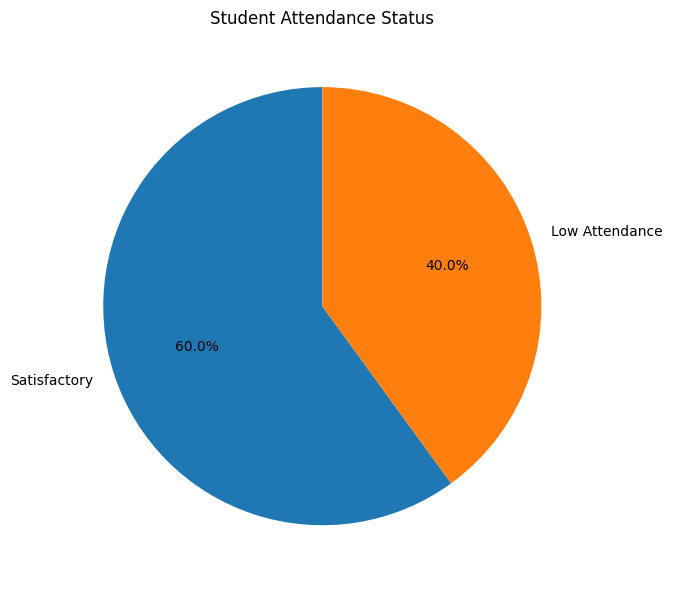

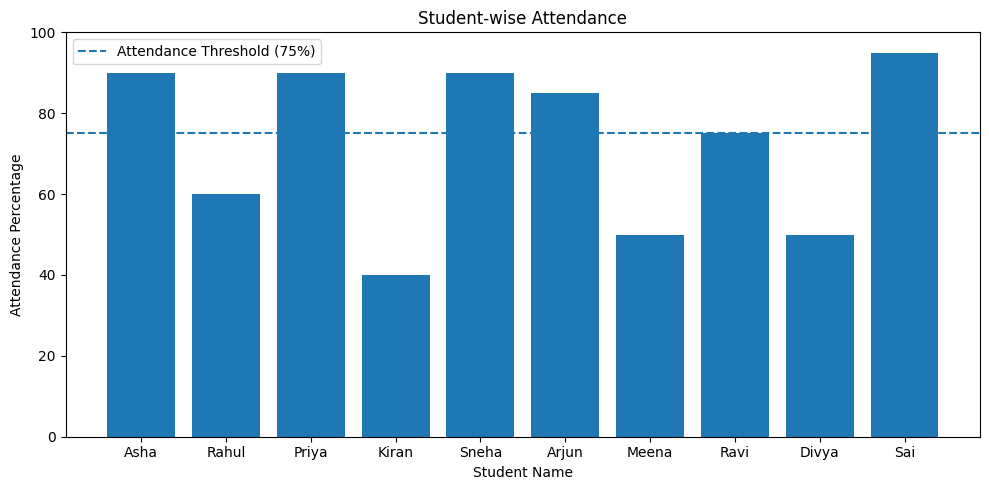


ML MODEL EVALUATION
Model Accuracy: 93.00%

Classification Report:
              precision    recall  f1-score   support

 Not At Risk       0.75      0.69      0.72        26
     At Risk       0.95      0.97      0.96       174

    accuracy                           0.93       200
   macro avg       0.85      0.83      0.84       200
weighted avg       0.93      0.93      0.93       200

Confusion Matrix:
 [[ 18   8]
 [  6 168]]


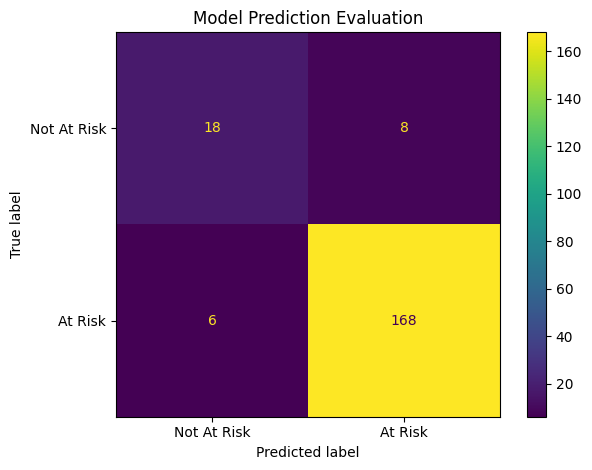


NEW STUDENT RISK ESTIMATION
Attendance: 90%
Absences: 1
Assignment Completion: 95%
Predicted Category: Not At Risk
Estimated Risk Probability: 4.03%


In [3]:

# PROGRAM 2: STUDENT ATTENDANCE TRACKER
# Correct Calculations + Pie Chart + Bar Graph + ML Model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------
# 1. STUDENT ATTENDANCE DATA
# ------------------------------------------------
df = pd.DataFrame({
    "Student": ["Asha", "Rahul", "Priya", "Kiran", "Sneha",
                "Arjun", "Meena", "Ravi", "Divya", "Sai"],
    "Total_Classes": [100, 100, 80, 100, 90, 100, 80, 100, 90, 100],
    "Attended": [90, 60, 72, 40, 81, 85, 40, 75, 45, 95]
})

# Validate records
assert (df["Total_Classes"] > 0).all()
assert (df["Attended"] >= 0).all()
assert (df["Attended"] <= df["Total_Classes"]).all()

# Correct calculations
df["Absent"] = df["Total_Classes"] - df["Attended"]

df["Attendance_Percentage"] = (
    df["Attended"] / df["Total_Classes"] * 100
).round(2)

THRESHOLD = 75

df["Status"] = np.where(
    df["Attendance_Percentage"] < THRESHOLD,
    "Low Attendance",
    "Satisfactory"
)

print("=" * 60)
print("STUDENT ATTENDANCE REPORT")
print("=" * 60)
print(df.to_string(index=False))

print("\nAverage Attendance:",
      round(df["Attendance_Percentage"].mean(), 2), "%")

print("Low Attendance Students:",
      (df["Status"] == "Low Attendance").sum())


# ------------------------------------------------
# 2. PIE CHART: ATTENDANCE STATUS
# ------------------------------------------------
status_counts = df["Status"].value_counts().reindex(
    ["Satisfactory", "Low Attendance"],
    fill_value=0
)

plt.figure(figsize=(7, 6))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Student Attendance Status")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 3. BAR GRAPH: INDIVIDUAL ATTENDANCE
# ------------------------------------------------
plt.figure(figsize=(10, 5))
plt.bar(df["Student"], df["Attendance_Percentage"])

plt.axhline(
    THRESHOLD,
    linestyle="--",
    label=f"Attendance Threshold ({THRESHOLD}%)"
)

plt.xlabel("Student Name")
plt.ylabel("Attendance Percentage")
plt.title("Student-wise Attendance")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 4. PREPARE SYNTHETIC ML DATA
# ------------------------------------------------
# Demonstration only:
# 0 = Not At Risk; 1 = At Risk
# Labels follow an artificial rule, not actual student outcomes.

rng = np.random.default_rng(42)
n = 1000

attendance = rng.uniform(40, 100, n)
absences = rng.integers(0, 12, n)
assignments = rng.uniform(20, 100, n)

y = (
    (attendance < 75) |
    (absences >= 5) |
    (assignments < 40)
).astype(int)

X = pd.DataFrame({
    "Attendance": attendance,
    "Absences": absences,
    "Assignment_Completion": assignments
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features and train Logistic Regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)


# ------------------------------------------------
# 5. EVALUATE THE MODEL
# ------------------------------------------------
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("\n" + "=" * 60)
print("ML MODEL EVALUATION")
print("=" * 60)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Not At Risk", "At Risk"],
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    predictions,
    labels=[0, 1]
)

print("Confusion Matrix:\n", cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not At Risk", "At Risk"]
).plot()

plt.title("Model Prediction Evaluation")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 6. PREDICT FOR A NEW STUDENT
# ------------------------------------------------
new_student = pd.DataFrame({
    "Attendance": [90],
    "Absences": [1],
    "Assignment_Completion": [95]
})

prediction = int(model.predict(new_student)[0])
risk_probability = model.predict_proba(new_student)[0][1]

print("\n" + "=" * 45)
print("NEW STUDENT RISK ESTIMATION")
print("=" * 45)

print("Attendance: 90%")
print("Absences: 1")
print("Assignment Completion: 95%")

print(
    "Predicted Category:",
    "At Risk" if prediction == 1 else "Not At Risk"
)
print(f"Estimated Risk Probability: {risk_probability * 100:.2f}%")



STUDENT ATTENDANCE REPORT
Student  Total_Classes  Attended  Attendance_Percentage  Absent         Status
   Asha            100        90             111.111111     -10 Low Attendance
  Rahul            100        60             166.666667     -40 Low Attendance
  Priya             80        72             111.111111      -8 Low Attendance
  Kiran            100        40             250.000000     -60 Low Attendance
  Sneha             90        81             111.111111      -9 Low Attendance
  Arjun            100        85             117.647059     -15 Low Attendance
  Meena             80        40             200.000000     -40 Low Attendance
   Ravi            100        75             133.333333     -25 Low Attendance
  Divya             90        45             200.000000     -45 Low Attendance
    Sai            100        95             105.263158      -5 Low Attendance


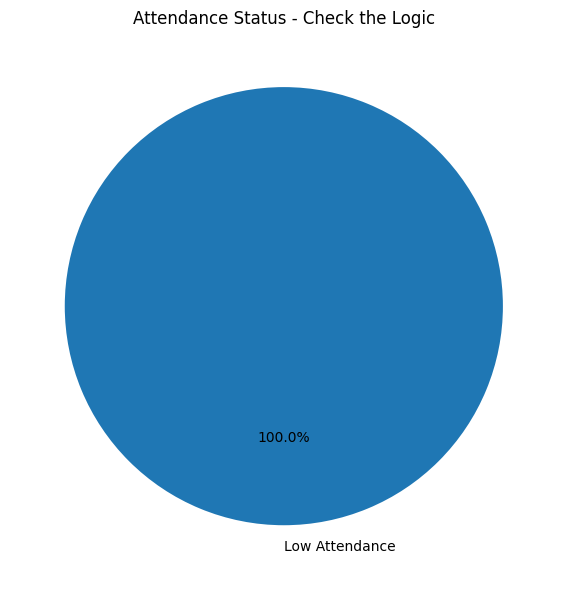

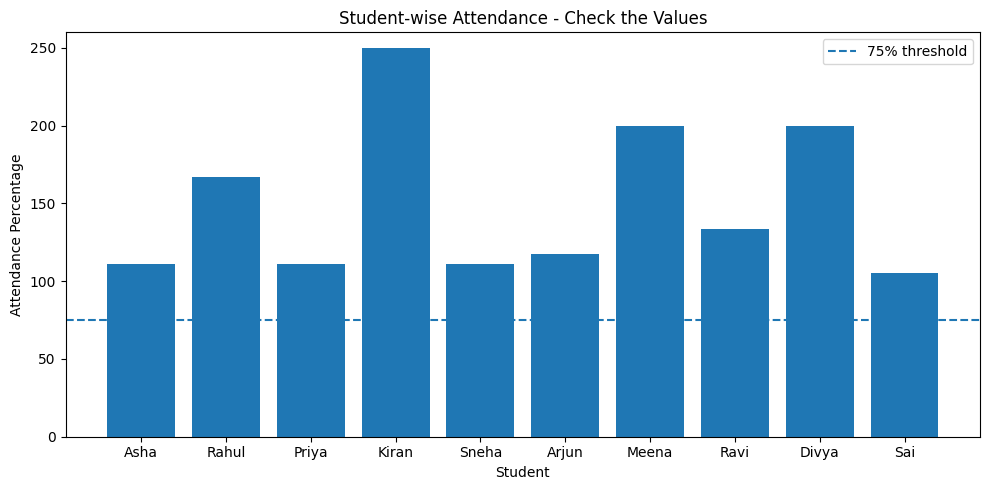


MODEL ACCURACY: 93.75 %

Confusion Matrix - Investigate the orientation:
 [[ 19   7]
 [  3 131]]

Predicted Category: At Risk

Bug Hunt report exported to bug_hunt_attendance.csv


In [4]:
# PROGRAM 1: STUDENT ATTENDANCE TRACKER - BUG HUNT
# Intentionally incorrect logic for classroom debugging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# ------------------------------------------------------------
# 1. SAMPLE ATTENDANCE DATA
# ------------------------------------------------------------

df = pd.DataFrame({
    "Student": [
        "Asha", "Rahul", "Priya", "Kiran", "Sneha",
        "Arjun", "Meena", "Ravi", "Divya", "Sai"
    ],
    "Total_Classes": [100, 100, 80, 100, 90, 100, 80, 100, 90, 100],
    "Attended": [90, 60, 72, 40, 81, 85, 40, 75, 45, 95]
})

# BUG 1: Incorrect attendance percentage formula
df["Attendance_Percentage"] = (
    df["Total_Classes"] / df["Attended"] * 100
)

# BUG 2: Incorrect absent class formula
df["Absent"] = df["Attended"] - df["Total_Classes"]

# BUG 3: Reversed attendance status condition
df["Status"] = np.where(
    df["Attendance_Percentage"] >= 75,
    "Low Attendance",
    "Satisfactory"
)

print("\nSTUDENT ATTENDANCE REPORT")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 2. PIE CHART
# ------------------------------------------------------------

counts = df["Status"].value_counts()

plt.figure(figsize=(7, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Attendance Status - Check the Logic")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. BAR GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.bar(df["Student"], df["Attendance_Percentage"])
plt.axhline(75, linestyle="--", label="75% threshold")
plt.xlabel("Student")
plt.ylabel("Attendance Percentage")
plt.title("Student-wise Attendance - Check the Values")
plt.ylim(0, max(110, df["Attendance_Percentage"].max() + 10))
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. CREATE SYNTHETIC ML DATA
# ------------------------------------------------------------

rng = np.random.default_rng(42)
n = 800

attendance = rng.uniform(40, 100, n)
absences = rng.integers(0, 12, n)
assignments = rng.uniform(20, 100, n)

# Synthetic target:
# 0 = Not At Risk
# 1 = At Risk
y = (
    (attendance < 75) |
    (absences >= 5) |
    (assignments < 40)
).astype(int)

X = pd.DataFrame({
    "Attendance": attendance,
    "Absences": absences,
    "Assignment_Completion": assignments
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("\nMODEL ACCURACY:",
      round(accuracy_score(y_test, predictions) * 100, 2), "%")

# BUG 4: Confusion matrix uses reversed label arguments
cm = confusion_matrix(predictions, y_test)
print("\nConfusion Matrix - Investigate the orientation:\n", cm)

# ------------------------------------------------------------
# 5. NEW STUDENT PREDICTION
# ------------------------------------------------------------

new_student = pd.DataFrame({
    "Attendance": [90],
    "Absences": [1],
    "Assignment_Completion": [95]
})

result = model.predict(new_student)[0]

# BUG 5: Reversed prediction labels
print(
    "\nPredicted Category:",
    "At Risk" if result == 0 else "Not At Risk"
)

# ------------------------------------------------------------
# 6. CSV EXPORT
# ------------------------------------------------------------

df.to_csv("bug_hunt_attendance.csv", index=False)
print("\nBug Hunt report exported to bug_hunt_attendance.csv")

# ------------------------------------------------------------
# STUDENT TASKS
# ------------------------------------------------------------
# 1. Fix the attendance percentage formula.
# 2. Fix the absent classes calculation.
# 3. Correct the attendance status condition.
# 4. Correct the confusion matrix argument order.
# 5. Correct the model prediction label mapping.
# 6. Re-run the charts and compare the results.


Using sample attendance data.

STUDENT ATTENDANCE REPORT
Student  Total_Classes  Attended  Absent  Attendance_Percentage         Status
   Asha            100        90      10                   90.0   Satisfactory
  Rahul            100        60      40                   60.0 Low Attendance
  Priya             80        72       8                   90.0   Satisfactory
  Kiran            100        40      60                   40.0 Low Attendance
  Sneha             90        81       9                   90.0   Satisfactory
  Arjun            100        85      15                   85.0   Satisfactory
  Meena             80        40      40                   50.0 Low Attendance
   Ravi            100        75      25                   75.0   Satisfactory
  Divya             90        45      45                   50.0 Low Attendance
    Sai            100        95       5                   95.0   Satisfactory
   Neha            100        88      12                   88.0   Satisfac

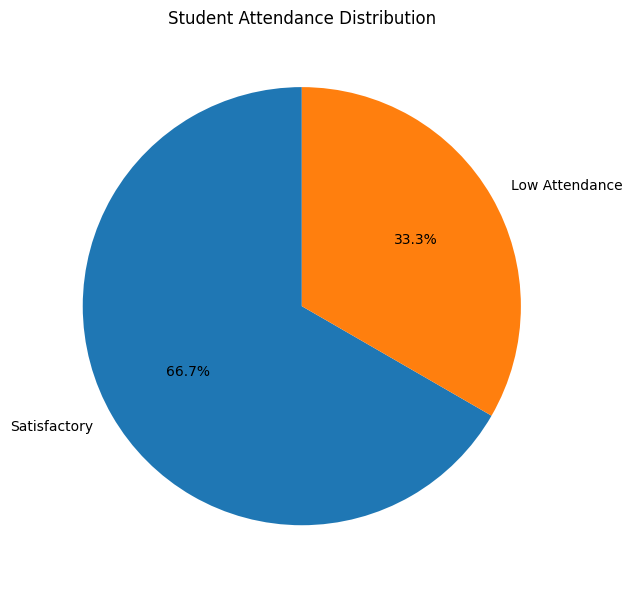

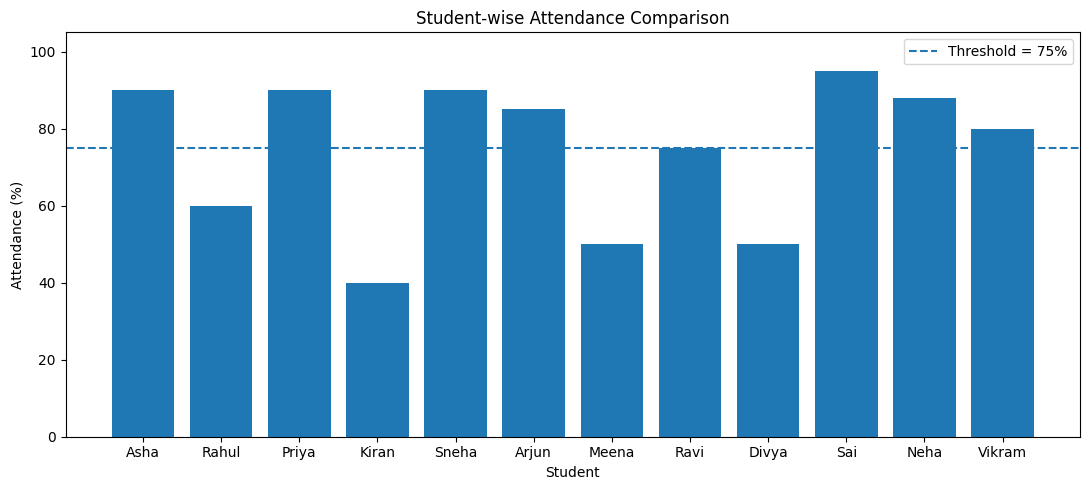

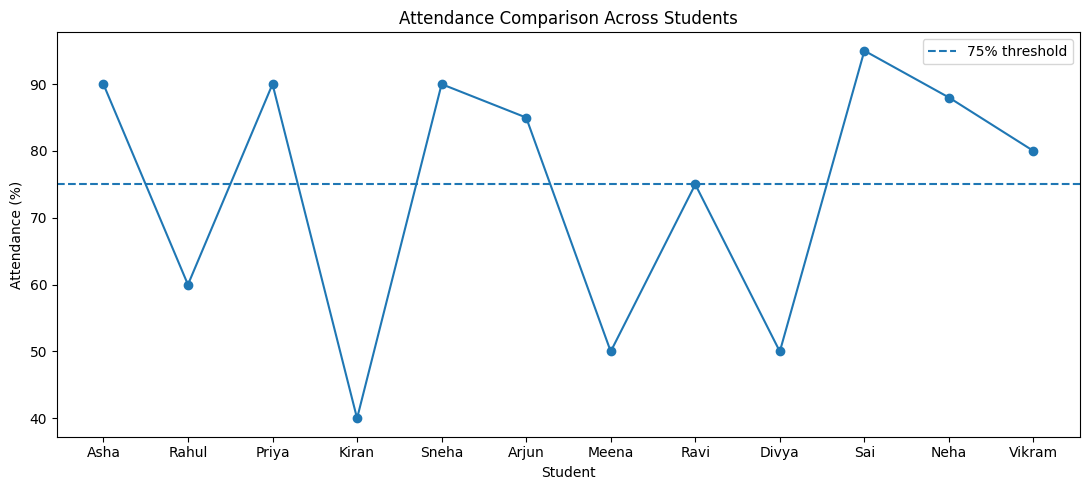

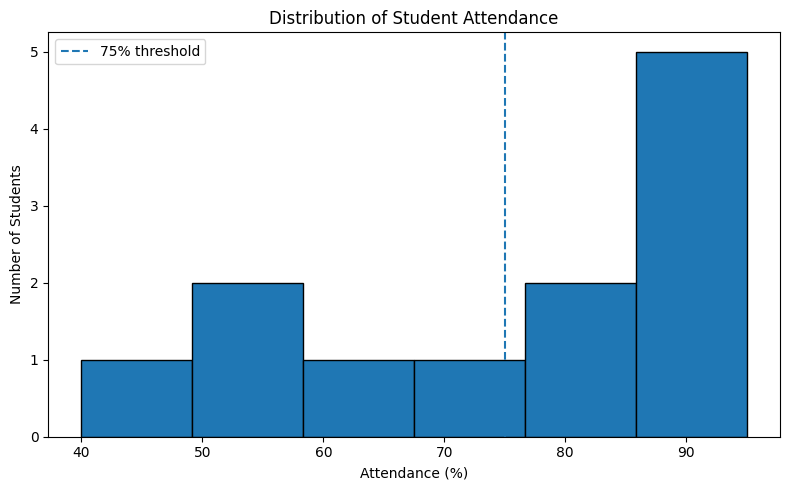


MODEL COMPARISON
              Model Accuracy Precision Recall F1_Score
Logistic Regression    0.943     0.955  0.981    0.968
      Random Forest    0.997     0.996  1.000    0.998

Selected model by F1-score: Random Forest

Classification Report:
              precision    recall  f1-score   support

 Not At Risk       1.00      0.97      0.99        40
     At Risk       1.00      1.00      1.00       260

    accuracy                           1.00       300
   macro avg       1.00      0.99      0.99       300
weighted avg       1.00      1.00      1.00       300



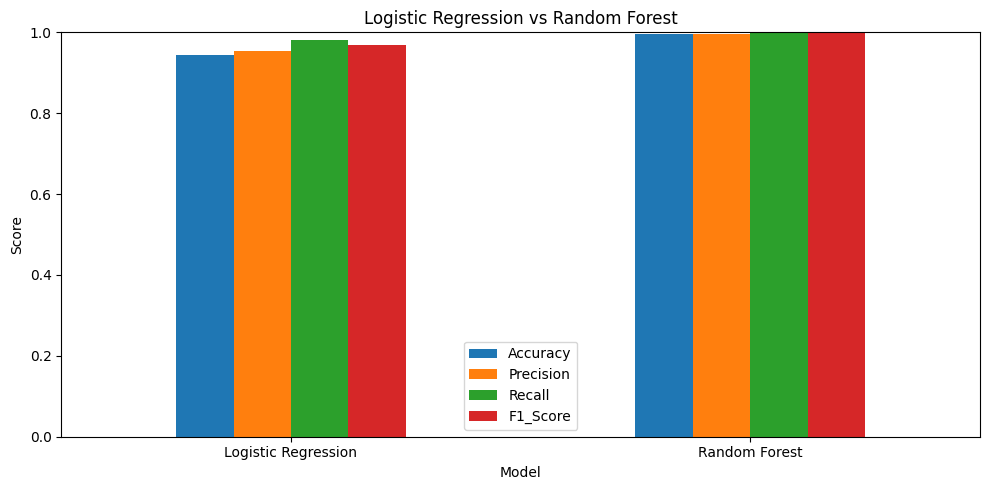

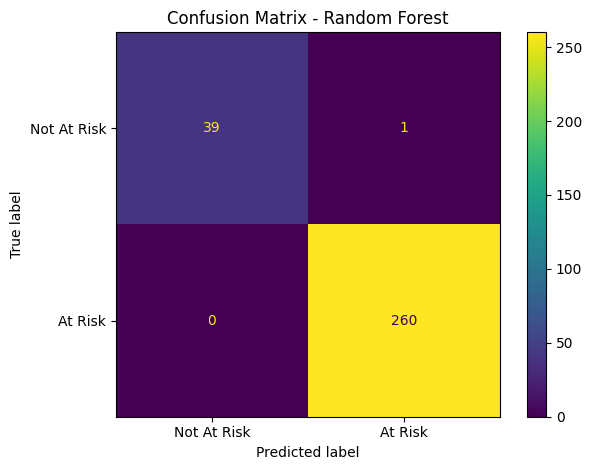


NEW STUDENT RISK ESTIMATE
Attendance: 90%
Consecutive Absences: 1
Assignment Completion: 95%
Predicted Category: Not At Risk
Estimated Risk Probability: 1.20%

Export completed:
1. attendance_report.csv
2. model_comparison.csv


In [5]:

# =========================================================
# PROGRAM 2: ADVANCED STUDENT ATTENDANCE TRACKER
# Correct calculations + visualizations + ML model comparison
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. LOAD CSV OR CREATE SAMPLE DATA
# ------------------------------------------------------------
# Optional CSV filename: attendance.csv
# Required columns:
# Student, Total_Classes, Attended

if os.path.exists("attendance.csv"):
    df = pd.read_csv("attendance.csv")
    print("Loaded existing file: attendance.csv")
else:
    df = pd.DataFrame({
        "Student": [
            "Asha", "Rahul", "Priya", "Kiran", "Sneha",
            "Arjun", "Meena", "Ravi", "Divya", "Sai",
            "Neha", "Vikram"
        ],
        "Total_Classes": [
            100, 100, 80, 100, 90, 100,
            80, 100, 90, 100, 100, 80
        ],
        "Attended": [
            90, 60, 72, 40, 81, 85,
            40, 75, 45, 95, 88, 64
        ]
    })
    print("Using sample attendance data.")

# ------------------------------------------------------------
# 2. VALIDATE INPUT DATA
# ------------------------------------------------------------

required_columns = {"Student", "Total_Classes", "Attended"}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"CSV is missing required columns: {sorted(missing_columns)}"
    )

if df.empty:
    raise ValueError("The attendance dataset is empty.")

if df["Student"].isna().any():
    raise ValueError("Student names cannot be missing.")

if df["Student"].duplicated().any():
    raise ValueError("Duplicate student names found.")

for col in ["Total_Classes", "Attended"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[["Total_Classes", "Attended"]].isna().any().any():
    raise ValueError("Attendance counts cannot be missing.")

if (df["Total_Classes"] <= 0).any():
    raise ValueError("Total classes must be greater than zero.")

if (df["Attended"] < 0).any():
    raise ValueError("Attended classes cannot be negative.")

if (df["Attended"] > df["Total_Classes"]).any():
    raise ValueError("Attended classes cannot exceed total classes.")

if not np.isfinite(
    df[["Total_Classes", "Attended"]].to_numpy(dtype=float)
).all():
    raise ValueError("Attendance data must contain finite numbers.")

# ------------------------------------------------------------
# 3. CORRECT ATTENDANCE CALCULATIONS
# ------------------------------------------------------------

THRESHOLD = 75

df["Absent"] = df["Total_Classes"] - df["Attended"]

df["Attendance_Percentage"] = (
    df["Attended"] / df["Total_Classes"] * 100
).round(2)

df["Status"] = np.where(
    df["Attendance_Percentage"] < THRESHOLD,
    "Low Attendance",
    "Satisfactory"
)

print("\n" + "=" * 65)
print("STUDENT ATTENDANCE REPORT")
print("=" * 65)

print(df.to_string(index=False))

print("\nTotal Students:", len(df))
print(
    "Average Attendance:",
    f"{df['Attendance_Percentage'].mean():.2f}%"
)
print(
    "Low Attendance Students:",
    int((df["Status"] == "Low Attendance").sum())
)
print(
    "Satisfactory Attendance Students:",
    int((df["Status"] == "Satisfactory").sum())
)

# ------------------------------------------------------------
# 4. PIE CHART: ATTENDANCE STATUS
# ------------------------------------------------------------

status_counts = df["Status"].value_counts().reindex(
    ["Satisfactory", "Low Attendance"],
    fill_value=0
)

plt.figure(figsize=(7, 6))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Student Attendance Distribution")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. BAR GRAPH: STUDENT-WISE ATTENDANCE
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))
plt.bar(df["Student"], df["Attendance_Percentage"])

plt.axhline(
    THRESHOLD,
    linestyle="--",
    label=f"Threshold = {THRESHOLD}%"
)

plt.xlabel("Student")
plt.ylabel("Attendance (%)")
plt.title("Student-wise Attendance Comparison")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. LINE GRAPH: ATTENDANCE COMPARISON
# ------------------------------------------------------------
# This compares students; it is not a chronological trend.
# Real attendance trends require dated attendance records.

plt.figure(figsize=(11, 5))
plt.plot(
    df["Student"],
    df["Attendance_Percentage"],
    marker="o"
)

plt.axhline(THRESHOLD, linestyle="--", label="75% threshold")
plt.xlabel("Student")
plt.ylabel("Attendance (%)")
plt.title("Attendance Comparison Across Students")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. HISTOGRAM: ATTENDANCE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.hist(df["Attendance_Percentage"], bins=6, edgecolor="black")
plt.axvline(THRESHOLD, linestyle="--", label="75% threshold")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Attendance")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. CREATE SYNTHETIC DATA FOR ML TRAINING
# ------------------------------------------------------------
# Teaching demonstration only.
# The artificial target is defined by a simple rule.
# It is NOT a real future-attendance outcome.

rng = np.random.default_rng(42)
n = 1500

previous_attendance = rng.uniform(40, 100, n)
consecutive_absences = rng.integers(0, 12, n)
assignment_completion = rng.uniform(20, 100, n)

X = pd.DataFrame({
    "Previous_Attendance": previous_attendance,
    "Consecutive_Absences": consecutive_absences,
    "Assignment_Completion": assignment_completion
})

# 0 = Not At Risk
# 1 = At Risk
y = (
    (previous_attendance < 75)
    | (consecutive_absences >= 5)
    | (assignment_completion < 40)
).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 9. TRAIN TWO MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("MODEL COMPARISON")
print("=" * 65)

print(
    results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.3f}".format,
            "Precision": "{:.3f}".format,
            "Recall": "{:.3f}".format,
            "F1_Score": "{:.3f}".format
        }
    )
)

# Compare models using F1-score.
# This is a teaching choice; real projects should choose
# metrics according to their goals and error costs.

best_name = results_df.sort_values(
    "F1_Score",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("\nSelected model by F1-score:", best_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["Not At Risk", "At Risk"],
    zero_division=0
))

# ------------------------------------------------------------
# 10. MODEL COMPARISON CHART
# ------------------------------------------------------------

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score"]
].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))

plt.ylabel("Score")
plt.title("Logistic Regression vs Random Forest")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not At Risk", "At Risk"]
).plot()

plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. PREDICT A NEW STUDENT
# ------------------------------------------------------------

new_student = pd.DataFrame({
    "Previous_Attendance": [90],
    "Consecutive_Absences": [1],
    "Assignment_Completion": [95]
})

risk_prediction = int(best_model.predict(new_student)[0])
risk_probability = best_model.predict_proba(new_student)[0][1]

print("\n" + "=" * 50)
print("NEW STUDENT RISK ESTIMATE")
print("=" * 50)

print("Attendance: 90%")
print("Consecutive Absences: 1")
print("Assignment Completion: 95%")

print(
    "Predicted Category:",
    "At Risk" if risk_prediction == 1 else "Not At Risk"
)
print(f"Estimated Risk Probability: {risk_probability:.2%}")

# ------------------------------------------------------------
# 13. EXPORT REPORTS TO CSV
# ------------------------------------------------------------

df.to_csv("attendance_report.csv", index=False)
results_df.to_csv("model_comparison.csv", index=False)

print("\nExport completed:")
print("1. attendance_report.csv")
print("2. model_comparison.csv")
